# California Housing Data

This notebook explores the housing data, prepares a few features, and checks selected numeric distributions.


In [592]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_original = pd.read_csv('data/housing.csv')
df = pd.read_csv('data/housing.csv')

In [593]:
import random
import numpy as np
import torch

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)
print(f"Using device: {DEVICE}")

if torch.backends.mps.is_available():
    torch.mps.manual_seed(seed)

# Part 1: Exploratory Data Analysis (EDA)

Inspect the dataset, check missing values, and review feature distributions.


## Load and inspect the data

Load the CSV into a DataFrame, then preview its rows, columns, and category counts.


In [594]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [595]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [596]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

## Check and handle missing bedroom values

Count missing values, inspect rows with missing `total_bedrooms`, and remove those rows before calculations that use the column.

In [597]:
df.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [598]:
df[df['total_bedrooms'].isna()].describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,207.000000,207.000000,207.000000,207.000000,0.0,207.000000,207.000000,207.000000,207.000000
mean,-119.472560,35.497633,29.270531,2562.603865,NaN,1477.772947,510.024155,3.822244,206007.280193
std,2.001424,2.097298,11.964927,1787.269789,NaN,1057.448212,386.120704,1.955595,111638.214545
min,-124.130000,32.660000,4.000000,154.000000,NaN,37.000000,16.000000,0.852700,45800.000000
25%,-121.810000,33.970000,19.000000,1307.500000,NaN,781.000000,258.000000,2.564150,128750.000000
50%,-118.490000,34.200000,30.000000,2155.000000,NaN,1217.000000,427.000000,3.411500,175000.000000
75%,-117.985000,37.495000,38.000000,3465.000000,NaN,1889.500000,628.000000,4.615750,267700.000000
max,-114.590000,40.920000,52.000000,11709.000000,NaN,7604.000000,3589.000000,15.000100,500001.000000


In [599]:
df = df.dropna(subset=['total_bedrooms'])

## Prepare the categorical feature

Convert `ocean_proximity` into indicator columns so the categories are represented numerically.

In [600]:
if 'ocean_proximity' in df.columns:
    df = pd.get_dummies(df, columns=['ocean_proximity'], dtype=int)
df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0


## Review numeric summaries

Use descriptive statistics to check the ranges and typical values in the dataset.

In [601]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
count,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000
mean,-119.570689,35.633221,28.633094,2636.504233,537.870553,1424.946949,499.433465,3.871162,206864.413155,0.442128,0.317917,0.000245,0.111095,0.128615
std,2.003578,2.136348,12.591805,2185.269567,421.385070,1133.208490,382.299226,1.899291,115435.667099,0.496652,0.465678,0.015641,0.314257,0.334782
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-121.800000,33.930000,18.000000,1450.000000,296.000000,787.000000,280.000000,2.563700,119500.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.536500,179700.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,-118.010000,37.720000,37.000000,3143.000000,647.000000,1722.000000,604.000000,4.744000,264700.000000,1.000000,1.000000,0.000000,0.000000,0.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Inspect distributions before transformation

Use boxplots and histograms to look at house value, total rooms, and total bedrooms.

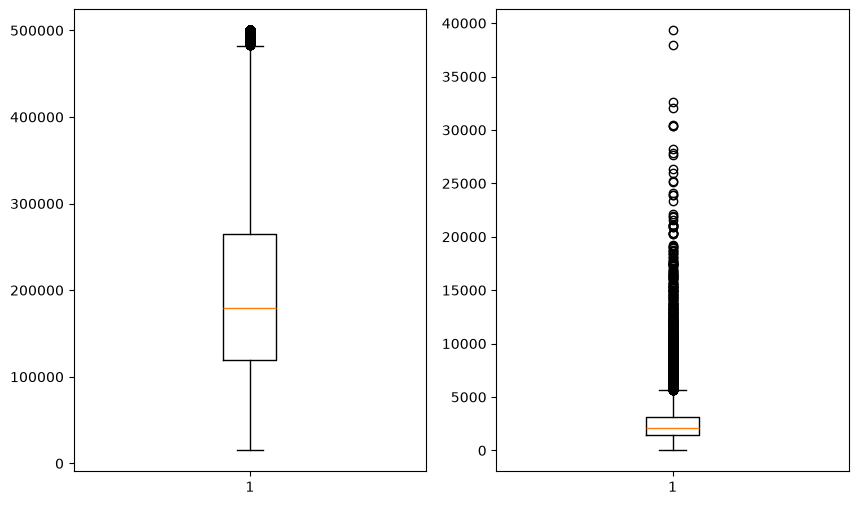

In [602]:
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.boxplot(df['median_house_value'])
plt.subplot(1, 2, 2)
plt.boxplot(df['total_rooms']);



plt.show()


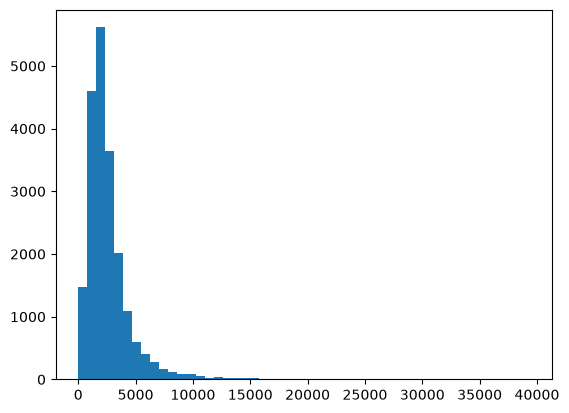

In [603]:
plt.hist(df['total_rooms'], bins=50)
plt.show()

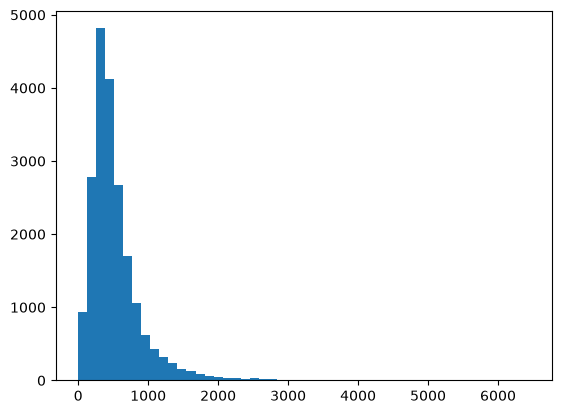

In [604]:
plt.hist(df['total_bedrooms'], bins=50)
plt.show()

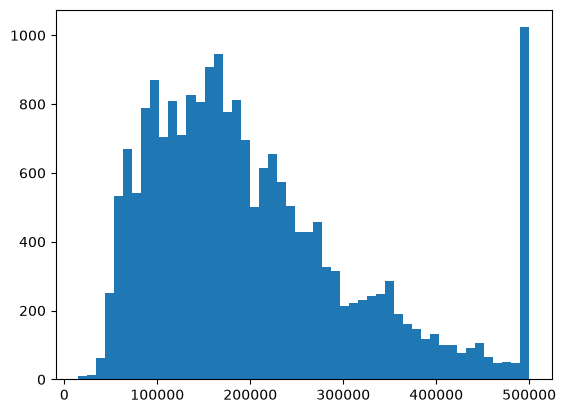

In [605]:
plt.hist(df['median_house_value'], bins=50)
plt.show()

In [606]:
(df['median_house_value'] == df['median_house_value'].max()).mean()

np.float64(0.04688494102677042)

In [607]:
df['median_house_value'].value_counts().head(10)

median_house_value
500001.0    958
137500.0    119
162500.0    116
112500.0    103
187500.0     92
225000.0     91
350000.0     79
87500.0      77
275000.0     65
150000.0     64
Name: count, dtype: int64

It seems that the maximum house value of 500,001 is a cap in the dataset. This may affect the distribution and should be considered in any modeling.

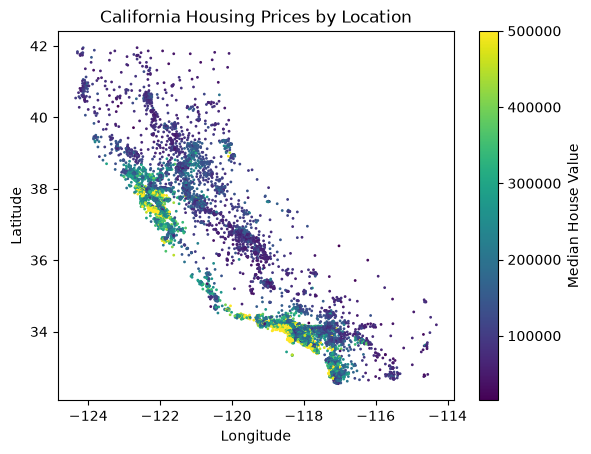

In [608]:
plt.scatter(df['longitude'], df['latitude'], c=df['median_house_value'], cmap='viridis', s=1)
plt.colorbar(label='Median House Value')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('California Housing Prices by Location')
plt.show()

![title](california_map.png)

As we can see from the plot, and from the map, the highest house values are concentrated in the San Francisco Bay Area and along the coast (near the big cities). The lowest values are found in the Central Valley and inland areas.

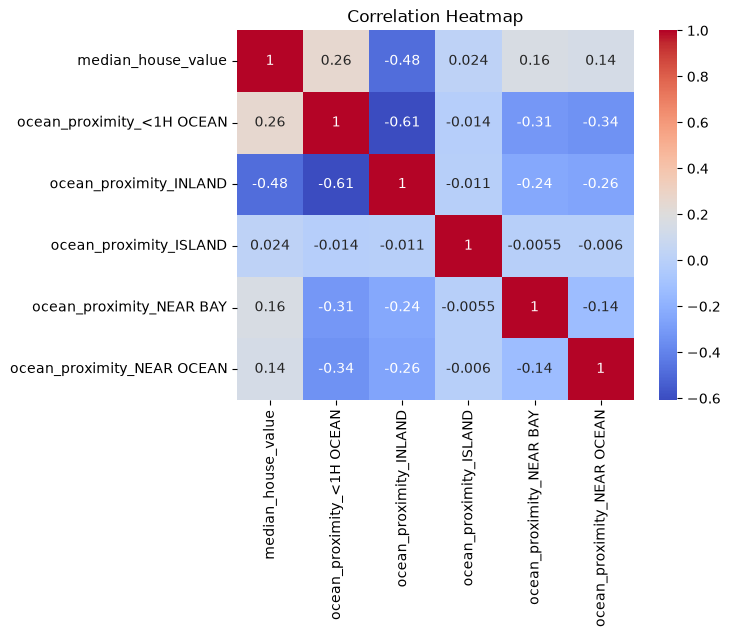

In [609]:
sns.heatmap(df[['median_house_value', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

# Part 2: Feature Engineering

Create household-level ratios and transform the room and bedroom counts.


In [610]:
df['rooms_per_household'] = (
    df['total_rooms'] / df['households']
)

df['bedrooms_per_room'] = (
    df['total_bedrooms'] / df['total_rooms']
)

df['population_per_household'] = (
    df['population'] / df['households']
)

## Reduce skew in room and bedroom counts

Apply `log1p`, which calculates `log(1 + x)`, to the room and bedroom counts.

In [611]:
df['log_total_rooms'] = np.log1p(df['total_rooms'])


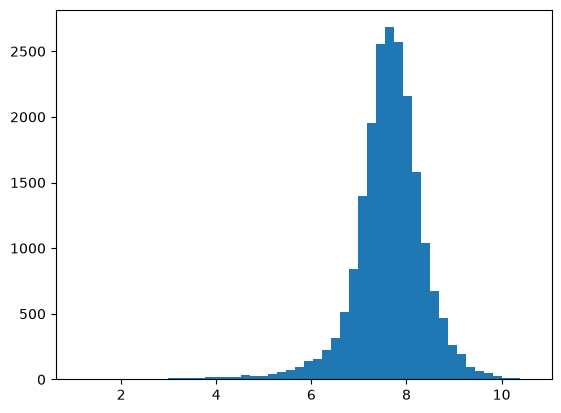

In [612]:
plt.hist(df['log_total_rooms'], bins=50)
plt.show()


In [613]:
df['log_total_bedrooms'] = np.log1p(df['total_bedrooms'])


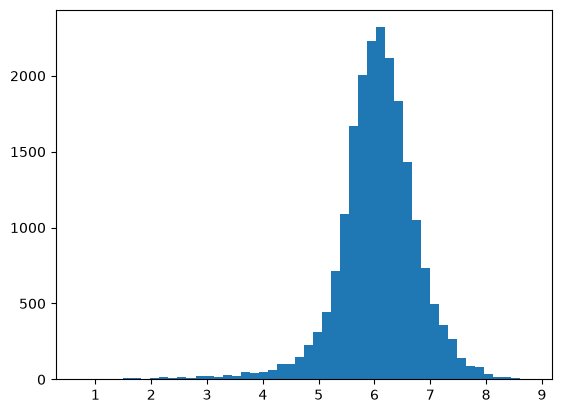

In [614]:
plt.hist(df['log_total_bedrooms'], bins=50)
plt.show()


In [615]:
df['latitude_near_ocean'] = (
    df['latitude'] *
    df['ocean_proximity_NEAR OCEAN']
)

df['longitude_inland'] = (
    df['longitude'] *
    df['ocean_proximity_INLAND']
)

df['latitude_near_bay'] = (
    df['latitude'] *
    df['ocean_proximity_NEAR BAY']
)
df['income_near_ocean'] = (
    df['median_income'] *
    df['ocean_proximity_NEAR OCEAN']
)

df['income_inland'] = (
    df['median_income'] *
    df['ocean_proximity_INLAND']
)

df['latitude_longitude'] = (
    df['latitude'] * df['longitude']
)

## Review the transformed data

Check the histograms and descriptive statistics after the transformations.

In [616]:
df.describe()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,...,bedrooms_per_room,population_per_household,log_total_rooms,log_total_bedrooms,latitude_near_ocean,longitude_inland,latitude_near_bay,income_near_ocean,income_inland,latitude_longitude
count,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,...,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000
mean,-119.570689,35.633221,28.633094,2636.504233,537.870553,1424.946949,499.433465,3.871162,206864.413155,0.442128,...,0.213039,3.071533,7.629543,6.054708,4.467596,-38.065195,4.199528,0.515282,1.020628,-4264.646279
std,2.003578,2.136348,12.591805,2185.269567,421.385070,1133.208490,382.299226,1.899291,115435.667099,0.496652,...,0.057983,10.438269,0.750260,0.726728,11.657591,55.767430,11.879491,1.523686,1.700451,323.948866
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000,0.000000,...,0.100000,0.692308,1.098612,0.693147,0.000000,-123.730000,0.000000,0.000000,0.000000,-5207.673000
25%,-121.800000,33.930000,18.000000,1450.000000,296.000000,787.000000,280.000000,2.563700,119500.000000,0.000000,...,0.175427,2.429032,7.280008,5.693732,0.000000,-117.660000,0.000000,0.000000,0.000000,-4601.363200
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.536500,179700.000000,0.000000,...,0.203162,2.817582,7.662938,6.077642,0.000000,0.000000,0.000000,0.000000,0.000000,-4060.373500
75%,-118.010000,37.720000,37.000000,3143.000000,647.000000,1722.000000,604.000000,4.744000,264700.000000,1.000000,...,0.239821,3.281513,8.053251,6.473891,0.000000,0.000000,0.000000,0.000000,2.080700,-4004.280600
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000,1.000000,...,1.000000,1243.333333,10.579514,8.771215,41.950000,-0.000000,38.340000,15.000100,15.000100,-3753.968400


In [617]:
wide_features = [
    'longitude',
    'latitude',
    'housing_median_age',
    'population',
    'households',
    'median_income',
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household',

    # Categorical features
    'ocean_proximity_<1H OCEAN',
    'ocean_proximity_INLAND',
    'ocean_proximity_ISLAND',
    'ocean_proximity_NEAR BAY',
    'ocean_proximity_NEAR OCEAN'
]

deep_features = [
    'longitude',
    'latitude',
    'housing_median_age',
    'population',
    'households',
    'median_income',
    'log_total_rooms',
    'log_total_bedrooms',
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household',

    # Categorical features
    'ocean_proximity_<1H OCEAN',
    'ocean_proximity_INLAND',
    'ocean_proximity_ISLAND',
    'ocean_proximity_NEAR BAY',
    'ocean_proximity_NEAR OCEAN'
]


In [618]:
wide_features = [
    'longitude', 'latitude', 'housing_median_age', 'population', 'households',
    'median_income', 'rooms_per_household', 'bedrooms_per_room',
    'population_per_household',
    'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
    'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
    'ocean_proximity_NEAR OCEAN'
]

deep_features = [
    'longitude', 'latitude', 'housing_median_age', 'population', 'households',
    'median_income', 'log_total_rooms', 'log_total_bedrooms',
    'rooms_per_household', 'bedrooms_per_room', 'population_per_household',
    'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
    'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
    'ocean_proximity_NEAR OCEAN'
]


In [619]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['median_house_value'])
y = df['median_house_value']
train_X, val_X, train_y, val_y = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [620]:
from sklearn.preprocessing import StandardScaler

numerical_features = [
    'longitude',
    'latitude',
    'housing_median_age',
    'population',
    'households',
    'median_income',
    'log_total_rooms',
    'log_total_bedrooms',
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household'
]

scaler = StandardScaler()
train_X = train_X.copy()
val_X = val_X.copy()
train_X.loc[:, numerical_features] = scaler.fit_transform(
    train_X[numerical_features]
)
val_X.loc[:, numerical_features] = scaler.transform(
    val_X[numerical_features]
)


In [621]:
from torch.utils.data import TensorDataset, DataLoader
import torch
import torch.nn as nn

SEED = 42
train_generator = torch.Generator().manual_seed(SEED)

train_X_wide = train_X[wide_features]
train_X_deep = train_X[deep_features]

train_X_wide_tensor = torch.tensor(train_X_wide.values, dtype=torch.float32)
train_X_deep_tensor = torch.tensor(train_X_deep.values, dtype=torch.float32)
train_y_tensor = torch.tensor(train_y.values, dtype=torch.float32).view(-1, 1)

train_data_wd = TensorDataset(train_X_wide_tensor, train_X_deep_tensor, train_y_tensor)
train_loader_wd = DataLoader(
    train_data_wd,
    batch_size=32,
    shuffle=True,
    generator=train_generator,
)


In [622]:
import random
import importlib
import torch
import models.model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

importlib.reload(models.model)
from models.model import Wide_and_Deep
model = Wide_and_Deep(
    wide_X=len(wide_features),
    deep_X=len(deep_features),
).to(DEVICE)


In [623]:
import random
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)


import importlib
import models.model

importlib.reload(models.model)
from models.model import Wide_and_Deep
model = Wide_and_Deep(
    wide_X = len(wide_features),
    deep_X = len(deep_features),
).to(DEVICE)

In [624]:
import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.1,
    weight_decay=1e-5
)

In [625]:
train_generator.manual_seed(SEED)
from models.train import train
importlib.reload(models.train)

train(model,optimizer,(nn.MSELoss()),train_loader_wd,n_epochs=10)

Epoch 1/10, Loss: 7285982413.9022
Epoch 2/10, Loss: 4108175135.5616
Epoch 3/10, Loss: 4001237719.4207
Epoch 4/10, Loss: 4014588764.0548
Epoch 5/10, Loss: 3868176364.2114
Epoch 6/10, Loss: 3829246119.5773
Epoch 7/10, Loss: 3776581268.2896
Epoch 8/10, Loss: 3751600386.2544
Epoch 9/10, Loss: 3712764827.8043
Epoch 10/10, Loss: 3702073620.0391


In [626]:
importlib.reload(models.train)
from models.train import evaluate
eval_data_loader_wd = DataLoader(
    TensorDataset(
        torch.tensor(val_X[wide_features].values, dtype=torch.float32),
        torch.tensor(val_X[deep_features].values, dtype=torch.float32),
        torch.tensor(val_y.values, dtype=torch.float32).view(-1, 1)
    ),
    batch_size=32,
    shuffle=False
)
mse = evaluate(model,eval_data_loader_wd,nn.MSELoss()).item()
rmse = np.sqrt(mse)
print(f"Validation RMSE: {rmse:.2f}")

Validation RMSE: 61900.25


In [627]:
mae = evaluate(model, eval_data_loader_wd, nn.L1Loss()).item()
print(f"Validation MAR: {mae:.2f}")

Validation MAR: 42448.21


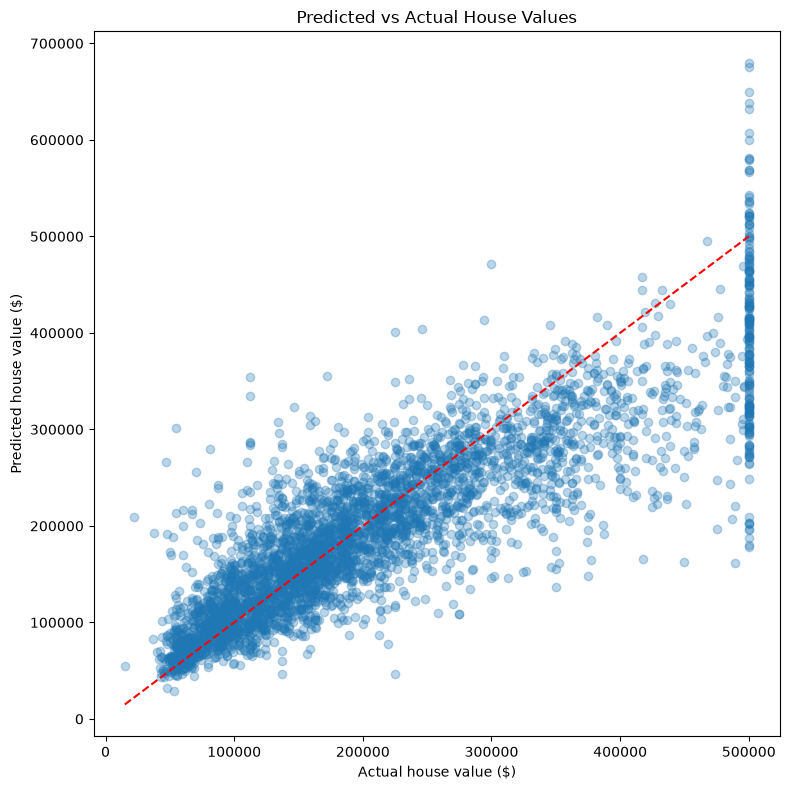

In [628]:
model.eval()

with torch.no_grad():
    predictions = model(
        torch.tensor(val_X[wide_features].values, dtype=torch.float32).to(DEVICE),
        torch.tensor(val_X[deep_features].values, dtype=torch.float32).to(DEVICE)
    )

y_pred = predictions.cpu().numpy().flatten()
y_actual = val_y

plt.figure(figsize=(8, 8))

plt.scatter(y_actual, y_pred, alpha=0.3)

plt.xlabel("Actual house value ($)")
plt.ylabel("Predicted house value ($)")
plt.title("Predicted vs Actual House Values")

plt.plot(
    [y_actual.min(), y_actual.max()],
    [y_actual.min(), y_actual.max()],
    'r--'
)

plt.tight_layout()
plt.show()

We see that the model predicts generally good, but there is some big outlier, predicted as 1.2million, while it costs 200k. And as I mentioned earlier 500k limitation makes a model to predict wrong values

In [629]:
y_pred_np = np.asarray(y_pred).flatten()
errors = y_pred_np - val_y.to_numpy()

worst_predictions = pd.DataFrame(
    {
        "actual": val_y.to_numpy(),
        "predicted": y_pred_np,
    },
    index=val_y.index,
)
worst_predictions["error"] = (
    worst_predictions["predicted"] - worst_predictions["actual"]
)
worst_predictions["abs_error"] = worst_predictions["error"].abs()

worst_predictions = worst_predictions.nlargest(10, "abs_error")
display(worst_predictions)


,actual,predicted,error,abs_error
489,489600.0,161716.468750,-327883.531250,327883.531250
10448,500001.0,177789.718750,-322211.281250,322211.281250
12069,500001.0,180279.000000,-319722.000000,319722.000000
4823,500000.0,187031.890625,-312968.109375,312968.109375
12138,500001.0,195503.906250,-304497.093750,304497.093750
16642,500001.0,196973.578125,-303027.421875,303027.421875
5354,500001.0,202016.546875,-297984.453125,297984.453125
4009,500001.0,203189.515625,-296811.484375,296811.484375
15624,500001.0,203467.515625,-296533.484375,296533.484375
10617,500001.0,209118.671875,-290882.328125,290882.328125


In [630]:
new_df = df.loc[worst_predictions.index].join(worst_predictions)
new_df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,...,latitude_near_ocean,longitude_inland,latitude_near_bay,income_near_ocean,income_inland,latitude_longitude,actual,predicted,error,abs_error
489,-122.25,37.86,48.0,2153.0,517.0,1656.0,459.0,3.0417,489600.0,0,...,0.0,-0.00,37.86,0.0000,0.0000,-4628.3850,489600.0,161716.468750,-327883.531250,327883.531250
10448,-117.67,33.47,22.0,2728.0,616.0,1081.0,566.0,1.6393,500001.0,1,...,0.0,-0.00,0.00,0.0000,0.0000,-3938.4149,500001.0,177789.718750,-322211.281250,322211.281250
12069,-117.55,33.83,6.0,502.0,76.0,228.0,65.0,4.2386,500001.0,0,...,0.0,-117.55,0.00,0.0000,4.2386,-3976.7165,500001.0,180279.000000,-319722.000000,319722.000000
4823,-118.31,34.05,26.0,1809.0,640.0,2543.0,640.0,2.3536,500000.0,1,...,0.0,-0.00,0.00,0.0000,0.0000,-4028.4555,500000.0,187031.890625,-312968.109375,312968.109375
12138,-117.22,33.87,16.0,56.0,7.0,39.0,14.0,2.6250,500001.0,0,...,0.0,-117.22,0.00,0.0000,2.6250,-3970.2414,500001.0,195503.906250,-304497.093750,304497.093750
16642,-120.67,35.30,19.0,1540.0,715.0,1799.0,635.0,0.7025,500001.0,0,...,35.3,-0.00,0.00,0.7025,0.0000,-4259.6510,500001.0,196973.578125,-303027.421875,303027.421875
5354,-118.41,34.03,33.0,1730.0,386.0,994.0,363.0,3.7277,500001.0,1,...,0.0,-0.00,0.00,0.0000,0.0000,-4029.4923,500001.0,202016.546875,-297984.453125,297984.453125
4009,-118.57,34.17,31.0,1950.0,383.0,870.0,357.0,3.1875,500001.0,1,...,0.0,-0.00,0.00,0.0000,0.0000,-4051.5369,500001.0,203189.515625,-296811.484375,296811.484375
15624,-122.41,37.80,52.0,812.0,252.0,629.0,247.0,2.5875,500001.0,0,...,0.0,-0.00,37.80,0.0000,0.0000,-4627.0980,500001.0,203467.515625,-296533.484375,296533.484375
10617,-117.81,33.68,4.0,1545.0,304.0,788.0,296.0,4.5469,500001.0,1,...,0.0,-0.00,0.00,0.0000,0.0000,-3967.8408,500001.0,209118.671875,-290882.328125,290882.328125


As we can see, our do very bad at 500k, which is the maximum value in the dataset. So we can remove those rows and rebuild the model to see if it improves the performance.

# Experiment 2 - Remove rows with maximum value of 500k and rebuild the model

In [631]:
df_dropped = df[df['median_house_value'] < 500001].copy()

In [632]:
# Rebuild the split and preprocessing after removing the selected row.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_dropped.drop(columns=['median_house_value'])
y = df_dropped['median_house_value']
train_X, val_X, train_y, val_y = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
train_X = train_X.copy()
val_X = val_X.copy()
train_X.loc[:, numerical_features] = scaler.fit_transform(
    train_X[numerical_features]
)
val_X.loc[:, numerical_features] = scaler.transform(
    val_X[numerical_features]
)

train_X_wide = train_X[wide_features]
train_X_deep = train_X[deep_features]
train_data_wd = TensorDataset(
    torch.tensor(train_X_wide.values, dtype=torch.float32),
    torch.tensor(train_X_deep.values, dtype=torch.float32),
    torch.tensor(train_y.values, dtype=torch.float32).view(-1, 1),
)
train_generator = torch.Generator().manual_seed(SEED)
train_loader_wd = DataLoader(
    train_data_wd, batch_size=32, shuffle=True, generator=train_generator
)

eval_data_loader_wd = DataLoader(
    TensorDataset(
        torch.tensor(val_X[wide_features].values, dtype=torch.float32),
        torch.tensor(val_X[deep_features].values, dtype=torch.float32),
        torch.tensor(val_y.values, dtype=torch.float32).view(-1, 1),
    ),
    batch_size=32,
    shuffle=False,
)

# Reset the random state before initializing the replacement model.
import random
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

model = Wide_and_Deep(
    wide_X=len(wide_features),
    deep_X=len(deep_features),
).to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=0.1, weight_decay=1e-5)


In [633]:
train_generator.manual_seed(SEED)
train(model,optimizer,(nn.MSELoss()),train_loader_wd,n_epochs=20)

Epoch 1/10, Loss: 5890106381.4045
Epoch 2/10, Loss: 3217306471.2936
Epoch 3/10, Loss: 3173777448.6078
Epoch 4/10, Loss: 3110114565.3881
Epoch 5/10, Loss: 3018152354.1684
Epoch 6/10, Loss: 2994662318.2587
Epoch 7/10, Loss: 3044902353.2156
Epoch 8/10, Loss: 2995817071.1786
Epoch 9/10, Loss: 2971014430.4887
Epoch 10/10, Loss: 2960871568.0329


In [634]:
mse = evaluate(model,eval_data_loader_wd,nn.MSELoss()).item()
rmse = np.sqrt(mse)
print(f"Validation RMSE: {rmse:.2f}")

Validation RMSE: 54540.50


In [635]:
mae = evaluate(model, eval_data_loader_wd, nn.L1Loss()).item()
print(f"Validation MAE: {mae:.2f}")

Validation MAE: 38201.83


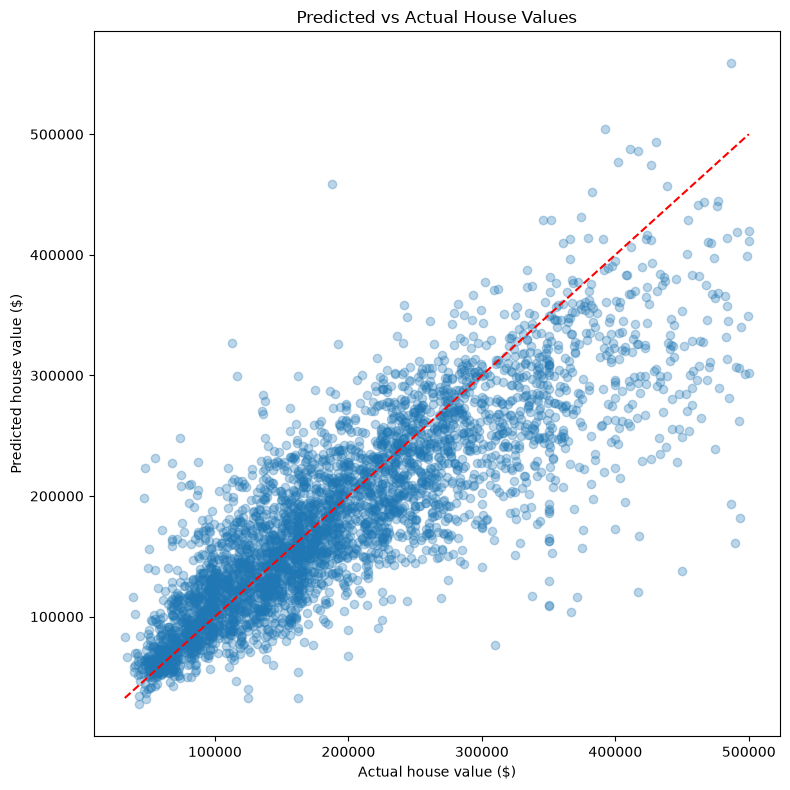

In [636]:
model.eval()

with torch.no_grad():
    predictions = model(
        torch.tensor(val_X[wide_features].values, dtype=torch.float32).to(DEVICE),
        torch.tensor(val_X[deep_features].values, dtype=torch.float32).to(DEVICE)
    )

y_pred = predictions.cpu().numpy().flatten()
y_actual = val_y

plt.figure(figsize=(8, 8))

plt.scatter(y_actual, y_pred, alpha=0.3)

plt.xlabel("Actual house value ($)")
plt.ylabel("Predicted house value ($)")
plt.title("Predicted vs Actual House Values")

plt.plot(
    [y_actual.min(), y_actual.max()],
    [y_actual.min(), y_actual.max()],
    'r--'
)

plt.tight_layout()
plt.show()

As we can see, after removing the rows with the maximum value of 500k, the model performs much better and the predictions are more aligned with the actual values. The RMSE and MAE have also improved, indicating a better fit to the data without the outliers. But, the problem is that the model will not be able to predict values above 500k, which is a limitation of the dataset. In a real-world scenario, we would want to have a more representative dataset that includes higher-value homes to improve the model's predictive capabilities.

# Experiment 3
I will be using old dataset, where the maximum values are not dropped. But I will try to work with correlation and feature engineering to get better results. So, the idea is to drop columns with very low correlation, so they are not fooling our model

In [637]:
df_new = df.copy()

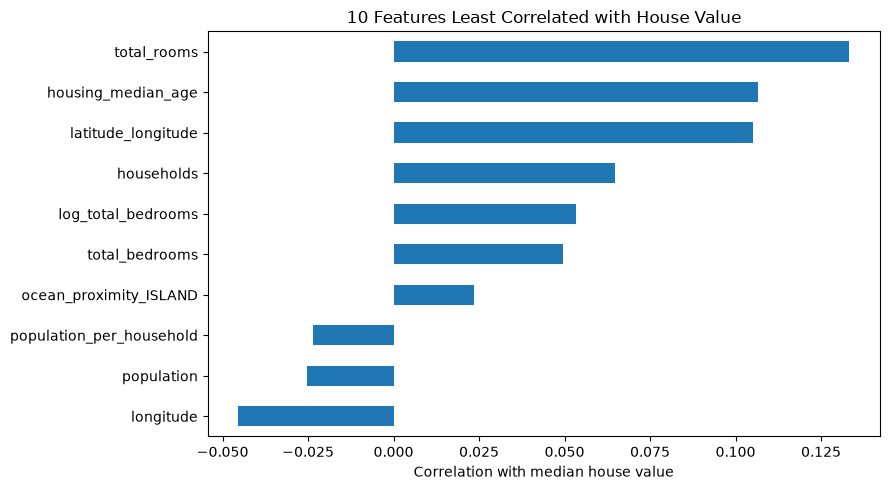

In [638]:
target = "median_house_value"

correlations = (
    df_new.select_dtypes(include="number")
      .corr()[target]
      .drop(target)
)

# Rank by correlation strength, then show the signed correlations
lowest = correlations.loc[correlations.abs().nsmallest(10).index].sort_values()


plt.figure(figsize=(9, 5))
lowest.plot(kind="barh")
plt.xlabel("Correlation with median house value")
plt.title("10 Features Least Correlated with House Value")
plt.tight_layout()
plt.show()

In [639]:
df_new.drop(columns=lowest.index[0:8], inplace=True)
df_new

,latitude,housing_median_age,total_rooms,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN,rooms_per_household,bedrooms_per_room,log_total_rooms,latitude_near_ocean,longitude_inland,latitude_near_bay,income_near_ocean,income_inland
0,37.88,41.0,880.0,8.3252,452600.0,0,0,1,0,6.984127,0.146591,6.781058,0.0,-0.00,37.88,0.0,0.0000
1,37.86,21.0,7099.0,8.3014,358500.0,0,0,1,0,6.238137,0.155797,8.867850,0.0,-0.00,37.86,0.0,0.0000
2,37.85,52.0,1467.0,7.2574,352100.0,0,0,1,0,8.288136,0.129516,7.291656,0.0,-0.00,37.85,0.0,0.0000
3,37.85,52.0,1274.0,5.6431,341300.0,0,0,1,0,5.817352,0.184458,7.150701,0.0,-0.00,37.85,0.0,0.0000
4,37.85,52.0,1627.0,3.8462,342200.0,0,0,1,0,6.281853,0.172096,7.395108,0.0,-0.00,37.85,0.0,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,39.48,25.0,1665.0,1.5603,78100.0,0,1,0,0,5.045455,0.224625,7.418181,0.0,-121.09,0.00,0.0,1.5603
20636,39.49,18.0,697.0,2.5568,77100.0,0,1,0,0,6.114035,0.215208,6.548219,0.0,-121.21,0.00,0.0,2.5568
20637,39.43,17.0,2254.0,1.7000,92300.0,0,1,0,0,5.205543,0.215173,7.720905,0.0,-121.22,0.00,0.0,1.7000
20638,39.43,18.0,1860.0,1.8672,84700.0,0,1,0,0,5.329513,0.219892,7.528869,0.0,-121.32,0.00,0.0,1.8672


In [640]:
wide_features_new = df_new.columns.intersection(wide_features).tolist()
deep_features_new = df_new.columns.intersection(deep_features).tolist()
wide_features_new

['latitude',
 'housing_median_age',
 'median_income',
 'ocean_proximity_<1H OCEAN',
 'ocean_proximity_INLAND',
 'ocean_proximity_NEAR BAY',
 'ocean_proximity_NEAR OCEAN',
 'rooms_per_household',
 'bedrooms_per_room']

In [641]:
deep_features_new

['latitude',
 'housing_median_age',
 'median_income',
 'ocean_proximity_<1H OCEAN',
 'ocean_proximity_INLAND',
 'ocean_proximity_NEAR BAY',
 'ocean_proximity_NEAR OCEAN',
 'rooms_per_household',
 'bedrooms_per_room',
 'log_total_rooms']

In [655]:
numerical_features_new = df_new.drop(columns="median_house_value",inplace=False).select_dtypes(include="number").columns.tolist()
numerical_features_new.remove('total_rooms')
numerical_features_new

['latitude',
 'housing_median_age',
 'median_income',
 'ocean_proximity_<1H OCEAN',
 'ocean_proximity_INLAND',
 'ocean_proximity_NEAR BAY',
 'ocean_proximity_NEAR OCEAN',
 'rooms_per_household',
 'bedrooms_per_room',
 'log_total_rooms',
 'latitude_near_ocean',
 'longitude_inland',
 'latitude_near_bay',
 'income_near_ocean',
 'income_inland']

In [656]:
# Rebuild the split and preprocessing after removing the selected row.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
df_new = df_new.astype("float32")
X = df_new.drop(columns=['median_house_value'])
y = df_new['median_house_value']
train_X, val_X, train_y, val_y = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
train_X = train_X.copy()
val_X = val_X.copy()
train_X.loc[:, numerical_features_new] = scaler.fit_transform(
    train_X[numerical_features_new]
)
val_X.loc[:, numerical_features_new] = scaler.transform(
    val_X[numerical_features_new]
)

train_X_wide = train_X[wide_features_new]
train_X_deep = train_X[deep_features_new]
train_data_wd = TensorDataset(
    torch.tensor(train_X_wide.values, dtype=torch.float32),
    torch.tensor(train_X_deep.values, dtype=torch.float32),
    torch.tensor(train_y.values, dtype=torch.float32).view(-1, 1),
)
train_generator = torch.Generator().manual_seed(SEED)
train_loader_wd = DataLoader(
    train_data_wd, batch_size=32, shuffle=True, generator=train_generator
)

eval_data_loader_wd = DataLoader(
    TensorDataset(
        torch.tensor(val_X[wide_features_new].values, dtype=torch.float32),
        torch.tensor(val_X[deep_features_new].values, dtype=torch.float32),
        torch.tensor(val_y.values, dtype=torch.float32).view(-1, 1),
    ),
    batch_size=32,
    shuffle=False,
)

# Reset the random state before initializing the replacement model.
import random

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

model = Wide_and_Deep(
    wide_X=len(wide_features_new),
    deep_X=len(deep_features_new),
).to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=0.1, weight_decay=1e-5)


In [657]:
train_generator.manual_seed(SEED)
train(model,optimizer,(nn.MSELoss()),train_loader_wd,n_epochs=20)

Epoch 1/20, Loss: 8363696622.7162
Epoch 2/20, Loss: 4975297666.2544
Epoch 3/20, Loss: 4939738828.6497
Epoch 4/20, Loss: 4909631120.2818
Epoch 5/20, Loss: 4882831526.5753
Epoch 6/20, Loss: 4873824078.2779
Epoch 7/20, Loss: 4869357404.6810
Epoch 8/20, Loss: 4861634370.3796
Epoch 9/20, Loss: 4826348444.0548
Epoch 10/20, Loss: 4856371476.0391
Epoch 11/20, Loss: 4852953081.2368
Epoch 12/20, Loss: 4801937679.7808
Epoch 13/20, Loss: 4819460143.3425
Epoch 14/20, Loss: 4841007195.4286
Epoch 15/20, Loss: 4755610710.4188
Epoch 16/20, Loss: 4548289011.2250
Epoch 17/20, Loss: 4396155082.1448
Epoch 18/20, Loss: 4320750185.4560
Epoch 19/20, Loss: 4233809657.1115
Epoch 20/20, Loss: 4192872583.5147


In [658]:
mse = evaluate(model,eval_data_loader_wd,nn.MSELoss()).item()
rmse = np.sqrt(mse)
print(f"Validation RMSE: {rmse:.2f}")

Validation RMSE: 66018.28


In [659]:
mae = evaluate(model, eval_data_loader_wd, nn.L1Loss()).item()
print(f"Validation MAE: {mae:.2f}")

Validation MAE: 46243.38


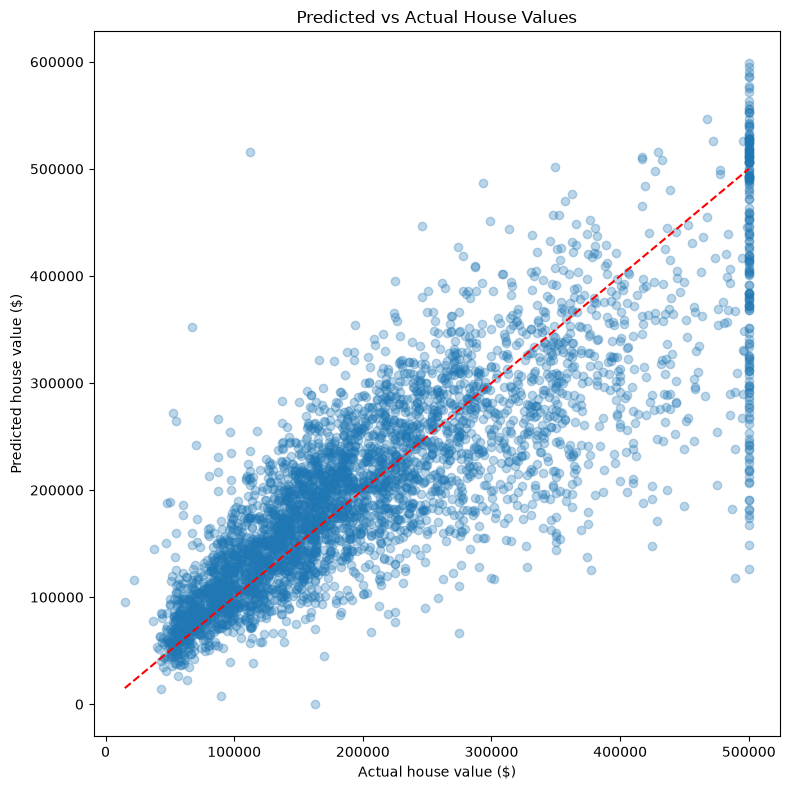

In [647]:
model.eval()

with torch.no_grad():
    predictions = model(
        torch.tensor(val_X[wide_features_new].values, dtype=torch.float32).to(DEVICE),
        torch.tensor(val_X[deep_features_new].values, dtype=torch.float32).to(DEVICE)
    )

y_pred = predictions.cpu().numpy().flatten()
y_actual = val_y

plt.figure(figsize=(8, 8))

plt.scatter(y_actual, y_pred, alpha=0.3)

plt.xlabel("Actual house value ($)")
plt.ylabel("Predicted house value ($)")
plt.title("Predicted vs Actual House Values")

plt.plot(
    [y_actual.min(), y_actual.max()],
    [y_actual.min(), y_actual.max()],
    'r--'
)

plt.tight_layout()
plt.show()

# Experiment 4
I will use dataset from Experiment 3, but I will drop the rows with maximum value of 500k, and see if it improves the performance. I will also use the same features as in Experiment 3, so we can compare the results.

In [649]:
df_new_dropped = df_new[df_new['median_house_value'] < 500001].copy()

In [650]:
# Rebuild the split and preprocessing after removing the selected row.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df_new = df_new.astype("float32")
X = df_new_dropped.drop(columns=['median_house_value'])
y = df_new_dropped['median_house_value']
train_X, val_X, train_y, val_y = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
train_X = train_X.copy()
val_X = val_X.copy()
train_X.loc[:, numerical_features_new] = scaler.fit_transform(
    train_X[numerical_features_new]
)
val_X.loc[:, numerical_features_new] = scaler.transform(
    val_X[numerical_features_new]
)

train_X_wide = train_X[wide_features_new]
train_X_deep = train_X[deep_features_new]
train_data_wd = TensorDataset(
    torch.tensor(train_X_wide.values, dtype=torch.float32),
    torch.tensor(train_X_deep.values, dtype=torch.float32),
    torch.tensor(train_y.values, dtype=torch.float32).view(-1, 1),
)
train_generator = torch.Generator().manual_seed(SEED)
train_loader_wd = DataLoader(
    train_data_wd, batch_size=32, shuffle=True, generator=train_generator
)

eval_data_loader_wd = DataLoader(
    TensorDataset(
        torch.tensor(val_X[wide_features_new].values, dtype=torch.float32),
        torch.tensor(val_X[deep_features_new].values, dtype=torch.float32),
        torch.tensor(val_y.values, dtype=torch.float32).view(-1, 1),
    ),
    batch_size=32,
    shuffle=False,
)

# Reset the random state before initializing the replacement model.
import random

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)

model = Wide_and_Deep(
    wide_X=len(wide_features_new),
    deep_X=len(deep_features_new),
).to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=0.1, weight_decay=1e-5)


In [651]:
train_generator.manual_seed(SEED)
train(model,optimizer,(nn.MSELoss()),train_loader_wd,n_epochs=20)

Epoch 1/20, Loss: 6633642394.8090
Epoch 2/20, Loss: 3890482099.7782
Epoch 3/20, Loss: 3854027564.6817
Epoch 4/20, Loss: 3827394310.3080
Epoch 5/20, Loss: 3781836115.5811
Epoch 6/20, Loss: 3756872108.9446
Epoch 7/20, Loss: 3796524164.7310
Epoch 8/20, Loss: 3747545119.9343
Epoch 9/20, Loss: 3793015266.8255
Epoch 10/20, Loss: 3752403144.5421
Epoch 11/20, Loss: 3771687468.1561
Epoch 12/20, Loss: 3745746369.3142
Epoch 13/20, Loss: 3767158350.5873
Epoch 14/20, Loss: 3722347111.5565
Epoch 15/20, Loss: 3660596303.3758
Epoch 16/20, Loss: 3654479391.6715
Epoch 17/20, Loss: 3613044214.5380
Epoch 18/20, Loss: 3621549143.5236
Epoch 19/20, Loss: 3572438056.6078
Epoch 20/20, Loss: 3500641228.7474


In [652]:
mse = evaluate(model,eval_data_loader_wd,nn.MSELoss()).item()
rmse = np.sqrt(mse)
print(f"Validation RMSE: {rmse:.2f}")

Validation RMSE: 58654.98


In [653]:
mae = evaluate(model, eval_data_loader_wd, nn.L1Loss()).item()
print(f"Validation MAE: {mae:.2f}")

Validation MAE: 41880.88


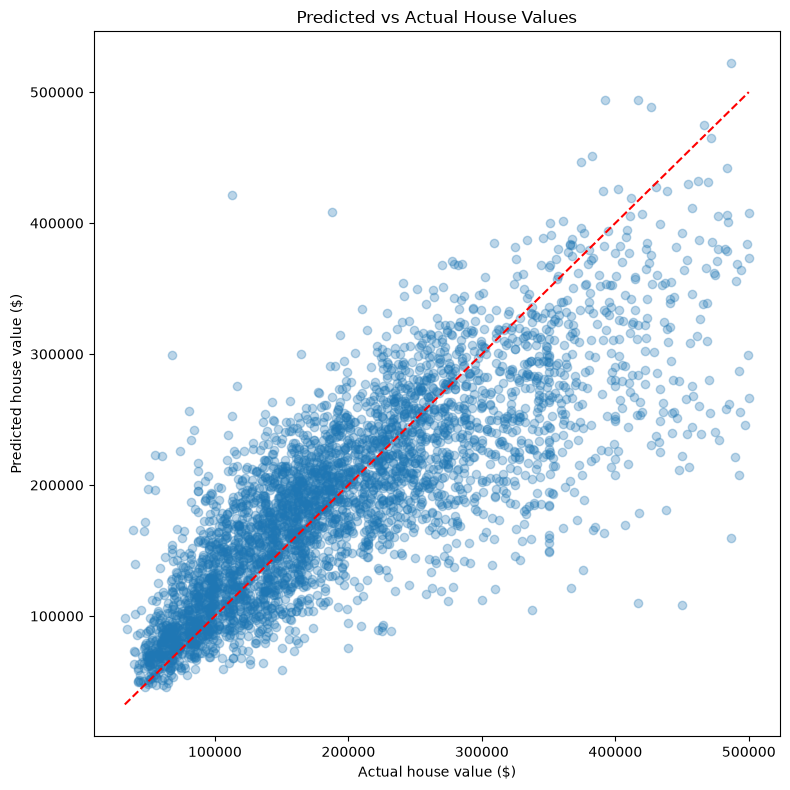

In [654]:
model.eval()

with torch.no_grad():
    predictions = model(
        torch.tensor(val_X[wide_features_new].values, dtype=torch.float32).to(DEVICE),
        torch.tensor(val_X[deep_features_new].values, dtype=torch.float32).to(DEVICE)
    )

y_pred = predictions.cpu().numpy().flatten()
y_actual = val_y

plt.figure(figsize=(8, 8))

plt.scatter(y_actual, y_pred, alpha=0.3)

plt.xlabel("Actual house value ($)")
plt.ylabel("Predicted house value ($)")
plt.title("Predicted vs Actual House Values")

plt.plot(
    [y_actual.min(), y_actual.max()],
    [y_actual.min(), y_actual.max()],
    'r--'
)

plt.tight_layout()
plt.show()
